# 05 · Decision Tree

A single CART tree. Depth, split and leaf sizes, feature subsampling and the split criterion are tuned. Whether the selected tree is actually shallow is reported as its depth and leaf count.

**Protocol (identical for every model; `src/controlled_framework.py`, `config.yaml`):**
- **Novelty-aware tuning.** Optuna TPE, the same number of trials for every model. The objective is the mean ROC-AUC over 5 *leave-attack-types-out* folds of `KDDTrain+`: each fold holds out a group of training attack types plus 1/5 of the normal rows, so the score measures how well held-out attack types are separated from normal traffic. The preprocessor is refit inside every fold.
- **Fixed parameters.** `class_weight=None` (or its equivalent) for every model; `random_state` = the run's seed.
- **Final refit.** On all of `KDDTrain+` with the **full** best-trial parameter set (tuned + fixed); `cf.check_final_params` asserts it.
- **Single evaluation on `KDDTest+`**, reported four ways:
  - at the fixed threshold 0.5;
  - threshold-free (ROC-AUC, PR-AUC, AUC of seen attacks vs normals, AUC of unseen attacks vs normals);
  - at FPR budgets of 1/2/5% read off the test ROC curve (ranking quality at a matched FPR);
  - at *deployable* thresholds, chosen so that 1/2/5% of the out-of-fold `KDDTrain+` normals exceed them. These use training data only, so the realised test FPR can differ from the budget.
- **Seeds.** The whole pipeline (tuning + refit + evaluation) runs once per seed in `config.yaml`. The primary seed (42) writes the model and the headline files; the other seeds write to `results/*/seeds/`.

**Outputs:** `models/decision_tree.joblib`, `results/metrics/decision_tree.json`, `results/predictions/decision_tree_predictions.csv`, `results/predictions/decision_tree_oof_train_scores.csv`, `results/tuning/decision_tree_trials.{json,csv}`, `results/*/seeds/decision_tree_seed*.*`, `results/tables/decision_tree_*.{csv,md}`, `results/figures/decision_tree/*.png`.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


## 1. Search space and fixed parameters

In [2]:
MODEL_NAME = "Decision Tree"
FIXED = {"class_weight": cf.CLASS_WEIGHT, "random_state": cf.SEED}
FOLD_JOBS = 5   # CV folds run in parallel for single-threaded estimators

def suggest(trial):
    return {
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
        "max_depth": trial.suggest_categorical("max_depth", [None, 3, 5, 10, 15, 20, 30]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", None]),
    }

from sklearn.tree import DecisionTreeClassifier

def factory(params):
    return DecisionTreeClassifier(**params)

def complexity(pipe, preds):
    clf = pipe.named_steps["clf"]
    return {"depth": int(clf.get_depth()), "n_leaves": int(clf.get_n_leaves()),
            "n_distinct_test_scores": int(preds["y_prob"].nunique())}

print("fixed:", FIXED)

fixed: {'class_weight': None, 'random_state': 42}


## 2. Primary seed: tune (novelty CV), refit on `KDDTrain+`, evaluate once on `KDDTest+`

In [3]:
data = cf.load_dataset()
res = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=cf.SEED, data=data, fold_jobs=FOLD_JOBS)
res.metrics["model_complexity"] = complexity(res.pipeline, res.predictions)
print()
print("best novelty CV AUC:", round(res.best_cv_auc, 4), "| fold AUCs:", np.round(res.best_cv_fold_aucs, 4))
print("final model parameters:", res.best_params)
print("model complexity:", res.metrics["model_complexity"])

  [Decision Tree | seed 42] trial 01/25  novelty CV AUC 0.7484 (±0.1054)


  [Decision Tree | seed 42] trial 02/25  novelty CV AUC 0.8225 (±0.1623)


  [Decision Tree | seed 42] trial 03/25  novelty CV AUC 0.7858 (±0.1511)


  [Decision Tree | seed 42] trial 04/25  novelty CV AUC 0.8112 (±0.1720)


  [Decision Tree | seed 42] trial 05/25  novelty CV AUC 0.5669 (±0.1934)


  [Decision Tree | seed 42] trial 06/25  novelty CV AUC 0.8013 (±0.1628)


... (16 outputs left out)

  [Decision Tree | seed 42] trial 23/25  novelty CV AUC 0.9155 (±0.0639)


  [Decision Tree | seed 42] trial 24/25  novelty CV AUC 0.8490 (±0.1764)


  [Decision Tree | seed 42] trial 25/25  novelty CV AUC 0.9120 (±0.0596)



best novelty CV AUC: 0.9157 | fold AUCs: [0.992  0.9262 0.976  0.8521 0.8321]
final model parameters: {'class_weight': None, 'random_state': 42, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 15, 'min_samples_leaf': 35, 'max_features': None}
model complexity: {'depth': 5, 'n_leaves': 24, 'n_distinct_test_scores': 20}


## 3. Tuning results

The cell also reports how far apart the best trials are relative to the fold-to-fold standard deviation. A spread smaller than one fold SD means this objective does not clearly separate the top configurations.

top-5 spread = 0.00291  vs  best-trial fold SD = 0.06420


,trial,mean_auc,std_auc,duration_seconds,class_weight,random_state,criterion,max_depth,min_samples_split,min_samples_leaf,max_features
0,19,0.915681,0.064198,2.37,None,42,entropy,5.0,15,35,NaN
1,20,0.915681,0.064198,2.36,None,42,entropy,5.0,15,35,NaN
2,9,0.915575,0.063755,2.45,None,42,entropy,5.0,17,27,NaN
3,22,0.915526,0.063925,2.50,None,42,entropy,5.0,17,30,NaN
4,21,0.912775,0.060728,2.50,None,42,entropy,5.0,10,25,NaN
5,24,0.911961,0.059578,2.43,None,42,entropy,5.0,10,11,NaN
6,15,0.909738,0.057467,2.57,None,42,entropy,5.0,19,8,NaN
7,18,0.909532,0.057382,2.59,None,42,entropy,5.0,13,5,NaN
8,14,0.909155,0.056885,2.33,None,42,entropy,5.0,17,10,NaN
9,6,0.885515,0.063008,1.17,None,42,gini,NaN,14,30,sqrt


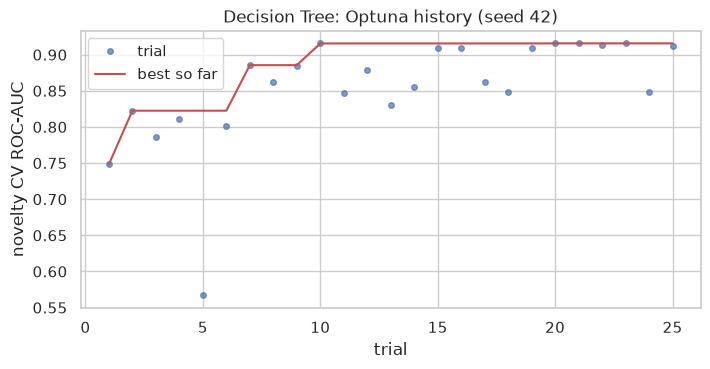

In [4]:
tt = cf.trials_table(res)
spread = tt["mean_auc"].iloc[0] - tt["mean_auc"].iloc[min(4, len(tt) - 1)]
print(f"top-5 spread = {spread:.5f}  vs  best-trial fold SD = {np.std(res.best_cv_fold_aucs):.5f}")
display(tt.head(10))

fig, ax = plt.subplots(figsize=(8, 3.6))
vals = [t["mean_auc"] for t in res.trials]
ax.plot(range(1, len(vals) + 1), vals, "o", ms=4, alpha=.7, label="trial")
ax.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), "-", color="#C44E52", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("novelty CV ROC-AUC"); ax.set_title(f"{MODEL_NAME}: Optuna history (seed {cf.SEED})"); ax.legend()
cf.save_figure(fig, "decision_tree", "tuning_history"); plt.show()

## 4. Test results (`KDDTest+`)

In [5]:
m = res.metrics
display(pd.Series(cf.summary_row(m)).to_frame(MODEL_NAME))
ops = pd.concat({"test ROC reading (matched test FPR)": pd.DataFrame(m["test_roc_operating_points"]).T,
                 "deployable (OOF-calibrated threshold)": pd.DataFrame(m["deployable_operating_points"]).T}).reset_index(names=["kind", "budget"])
cat = pd.DataFrame(m["attack_category_recall"]).T.reset_index(names="category")
strat = pd.DataFrame([{"category": c, "seen_n": v["seen"]["total_samples"], "seen_recall": v["seen"]["recall"],
                       "unseen_n": v["unseen"]["total_samples"], "unseen_recall": v["unseen"]["recall"]}
                      for c, v in m["category_stratified_seen_unseen_recall"].items()])
unseen = pd.DataFrame(m["per_unseen_attack_recall"]).T.reset_index(names="attack").sort_values("total_samples", ascending=False)
cf.save_table(ops, "decision_tree_operating_points")
cf.save_table(cat, "decision_tree_category_recall")
cf.save_table(strat, "decision_tree_category_stratified")
cf.save_table(unseen, "decision_tree_per_unseen_attack")
display(ops); display(strat); display(unseen)

,Decision Tree
model,Decision Tree
accuracy,0.780553
macro_f1,0.779882
attack_precision,0.965745
attack_recall,0.637107
false_positive_rate,0.029866
seen_recall,0.7558
unseen_recall,0.3496
generalization_drop_pp,40.62
reweighted_drop_pp,45.98


,kind,budget,threshold,fpr,attack_recall,seen_recall,unseen_recall
0,test ROC reading (matched test FPR),fpr_1pct,0.995018,0.004325,0.492402,0.668171,0.066667
1,test ROC reading (matched test FPR),fpr_2pct,0.960326,0.018229,0.547339,0.713090,0.145867
2,test ROC reading (matched test FPR),fpr_5pct,0.060075,0.044387,0.709031,0.854674,0.356267
3,deployable (OOF-calibrated threshold),fpr_1pct,0.485273,0.029866,0.637107,0.755808,0.349600
4,deployable (OOF-calibrated threshold),fpr_2pct,0.078680,0.039135,0.666485,0.796873,0.350667
5,deployable (OOF-calibrated threshold),fpr_5pct,0.029273,0.059629,0.803787,0.898602,0.574133


,category,seen_n,seen_recall,unseen_n,unseen_recall
0,DoS,5741,0.9974,1717,0.0419
1,Probe,1106,0.9973,1315,0.8517
2,R2L,2199,0.0164,688,0.1657
3,U2R,37,0.0000,30,0.1667


,attack,category,total_samples,detected,missed,recall
3,mscan,Probe,996,806,190,0.8092
0,apache2,DoS,737,58,679,0.0787
5,processtable,DoS,685,12,673,0.0175
10,snmpguess,R2L,331,0,331,0.0
7,saint,Probe,319,314,5,0.9843
2,mailbomb,DoS,293,0,293,0.0
9,snmpgetattack,R2L,178,0,178,0.0
1,httptunnel,R2L,133,110,23,0.8271
4,named,R2L,17,4,13,0.2353
6,ps,U2R,15,3,12,0.2


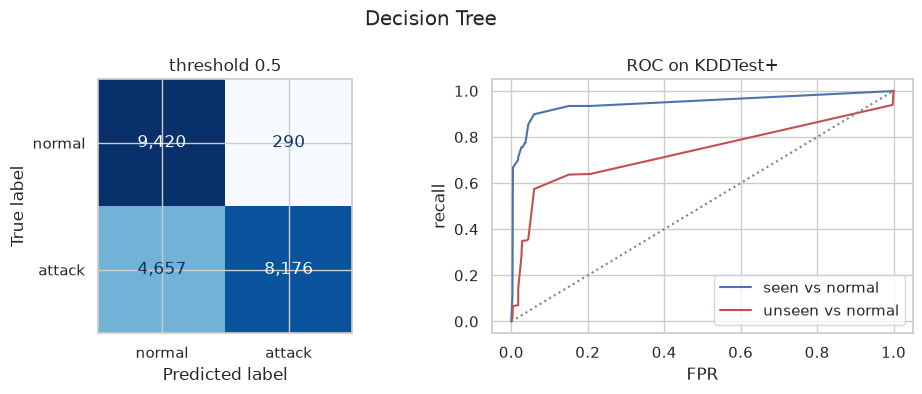

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(np.array(m["overall_metrics"]["confusion_matrix"]), display_labels=["normal", "attack"]).plot(
    ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("threshold 0.5")
p = res.predictions
for name, mask, col in [("seen vs normal", (p.y_true == 0) | ~p.is_unseen, "#4C72B0"), ("unseen vs normal", (p.y_true == 0) | p.is_unseen, "#C44E52")]:
    fpr, tpr, _ = roc_curve(p.y_true[mask], p.y_prob[mask]); axes[1].plot(fpr, tpr, color=col, label=name)
axes[1].plot([0, 1], [0, 1], ":", color="grey"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("recall"); axes[1].legend()
axes[1].set_title("ROC on KDDTest+")
fig.suptitle(MODEL_NAME); fig.tight_layout()
cf.save_figure(fig, "decision_tree", "confusion_and_roc"); plt.show()

## 5. Save primary-seed artifacts

In [7]:
paths = cf.save_experiment(res, primary=True)
for k, v in paths.items():
    print(f"{k:12s} {v.relative_to(PROJECT_ROOT)}")

metrics      results/metrics/decision_tree.json
predictions  results/predictions/decision_tree_predictions.csv
tuning_json  results/tuning/decision_tree_trials.json
tuning_csv   results/tuning/decision_tree_trials.csv
model        models/decision_tree.joblib
oof          results/predictions/decision_tree_oof_train_scores.csv


## 6. Remaining seeds (full pipeline per seed)

In [8]:
seed_rows = [cf.summary_row(res.metrics) | {"seed": cf.SEED, "best_novelty_cv_auc": res.best_cv_auc}]
for s in [s for s in cf.SEEDS if s != cf.SEED]:
    r = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=s, data=data, fold_jobs=FOLD_JOBS, verbose=False)
    r.metrics["model_complexity"] = complexity(r.pipeline, r.predictions)
    cf.save_experiment(r, primary=False)
    seed_rows.append(cf.summary_row(r.metrics) | {"seed": s, "best_novelty_cv_auc": r.best_cv_auc})
    print(f"seed {s}: CV AUC {r.best_cv_auc:.4f} | test unseen AUC {r.metrics['threshold_free']['roc_auc_unseen_vs_normal']:.4f} | "
          f"unseen recall@0.5 {r.metrics['seen_vs_unseen_recall']['unseen_recall']:.4f} | params { {k: v for k, v in r.best_params.items() if k not in FIXED} }")
    del r
seeds_tbl = pd.DataFrame(seed_rows)
cols = ["seed", "best_novelty_cv_auc", "macro_f1", "false_positive_rate", "seen_recall", "unseen_recall",
        "auc_seen_vs_normal", "auc_unseen_vs_normal", "unseen_recall@test_fpr_2pct", "test_fpr@oof_fpr_2pct", "unseen_recall@oof_fpr_2pct"]
seeds_tbl = seeds_tbl[cols]
cf.save_table(seeds_tbl, "decision_tree_seeds")
display(seeds_tbl)
display(seeds_tbl.drop(columns="seed").agg(["mean", "std"]).T)

seed 1: CV AUC 0.9013 | test unseen AUC 0.7951 | unseen recall@0.5 0.1557 | params {'criterion': 'entropy', 'max_depth': 15, 'min_samples_split': 17, 'min_samples_leaf': 39, 'max_features': 'sqrt'}


seed 2: CV AUC 0.9088 | test unseen AUC 0.7312 | unseen recall@0.5 0.3491 | params {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 9, 'min_samples_leaf': 4, 'max_features': None}


seed 3: CV AUC 0.9173 | test unseen AUC 0.7346 | unseen recall@0.5 0.3496 | params {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 14, 'min_samples_leaf': 43, 'max_features': None}


seed 4: CV AUC 0.9135 | test unseen AUC 0.7335 | unseen recall@0.5 0.3491 | params {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 21, 'max_features': None}


,seed,best_novelty_cv_auc,macro_f1,false_positive_rate,seen_recall,unseen_recall,auc_seen_vs_normal,auc_unseen_vs_normal,unseen_recall@test_fpr_2pct,test_fpr@oof_fpr_2pct,unseen_recall@oof_fpr_2pct
0,42,0.915681,0.779882,0.029866,0.7558,0.3496,0.946450,0.733611,0.145867,0.039135,0.350667
1,1,0.901293,0.754859,0.039341,0.7853,0.1557,0.948378,0.795077,0.107467,0.043563,0.291733
2,2,0.908837,0.779537,0.030793,0.7561,0.3491,0.945150,0.731238,0.214400,0.039135,0.351200
3,3,0.917330,0.779928,0.029866,0.7559,0.3496,0.946452,0.734612,0.145867,0.036869,0.350667
4,4,0.913513,0.779537,0.030793,0.7561,0.3491,0.945897,0.733539,0.214667,0.039135,0.353600


,mean,std
best_novelty_cv_auc,0.911331,0.006455
macro_f1,0.774749,0.011120
false_positive_rate,0.032132,0.004057
seen_recall,0.761840,0.013115
unseen_recall,0.310620,0.086603
auc_seen_vs_normal,0.946465,0.001195
auc_unseen_vs_normal,0.745615,0.027678
unseen_recall@test_fpr_2pct,0.165653,0.047295
test_fpr@oof_fpr_2pct,0.039567,0.002440
unseen_recall@oof_fpr_2pct,0.339573,0.026771


**Reading these numbers.** Seed-to-seed spread shows how much of any difference between models comes from training and tuning randomness rather than from the model family. The cross-model comparison is in `08_evaluation_comparison.ipynb`.